In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Basic checks

In [2]:
df=pd.read_csv("breast_cancer.csv")
df

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...
678,3,1,1,1,3,2,1,1,1,2
679,2,1,1,1,2,1,1,1,1,2
680,5,10,10,3,7,3,8,10,2,4
681,4,8,6,4,3,4,10,6,1,4


In [3]:
df.shape

(683, 10)

In [4]:
df.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2


In [5]:
df.tail()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
678,3,1,1,1,3,2,1,1,1,2
679,2,1,1,1,2,1,1,1,1,2
680,5,10,10,3,7,3,8,10,2,4
681,4,8,6,4,3,4,10,6,1,4
682,4,8,8,5,4,5,10,4,1,4


In [6]:
df.isnull().sum()

Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [7]:
df.duplicated().sum()

234

In [16]:
df1=df.drop_duplicates()
df1

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...
677,3,1,1,1,2,1,2,1,2,2
678,3,1,1,1,3,2,1,1,1,2
680,5,10,10,3,7,3,8,10,2,4
681,4,8,6,4,3,4,10,6,1,4


In [17]:
df1[df1.duplicated()]

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class


In [18]:
df1

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...
677,3,1,1,1,2,1,2,1,2,2
678,3,1,1,1,3,2,1,1,1,2
680,5,10,10,3,7,3,8,10,2,4
681,4,8,6,4,3,4,10,6,1,4


## EDA

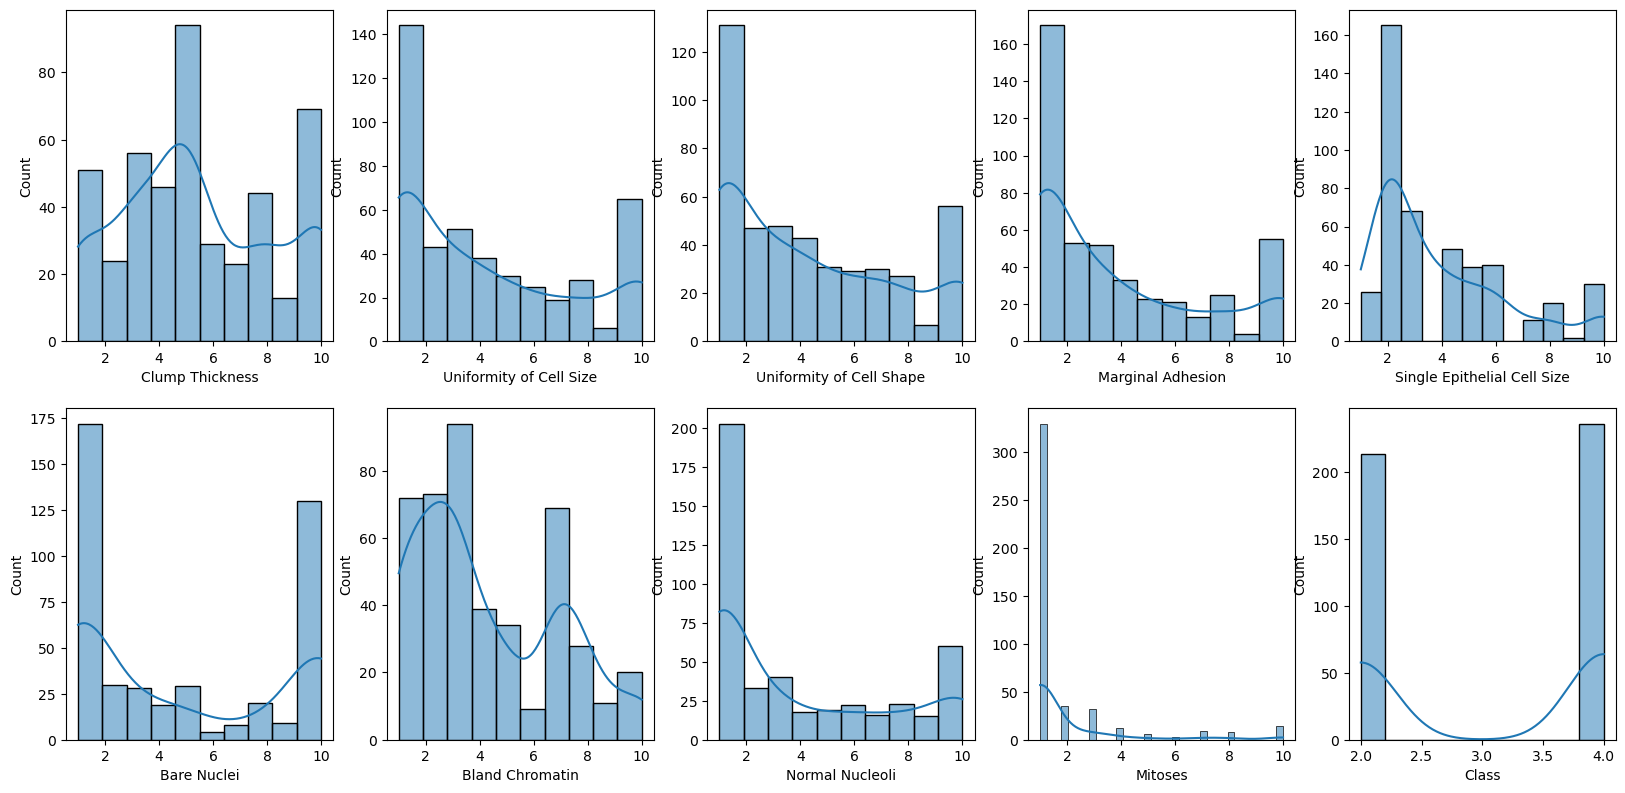

In [20]:
plt.figure(figsize=(20,25))
pos=1
for i in df1.columns:
    plt.subplot(5,5,pos)
    sns.histplot(df1[i],kde=True)
    pos=pos+1


    

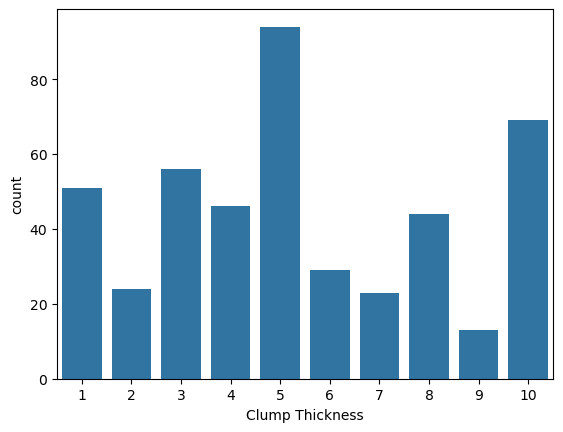

In [24]:
sns.countplot(x='Clump Thickness',data=df1)
plt.show()

## Data Preprocessing and Feature Engineering

In [27]:
res=df1.corr()
res

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
Clump Thickness,1.000000,0.570750,0.584082,0.379143,0.429917,0.508838,0.485863,0.444267,0.294359,0.670230
Uniformity of Cell Size,0.570750,1.000000,0.876916,0.638499,0.689472,0.590451,0.710705,0.650262,0.403411,0.758697
Uniformity of Cell Shape,0.584082,0.876916,1.000000,0.612859,0.650156,0.618310,0.684466,0.650739,0.381447,0.759500
Marginal Adhesion,0.379143,0.638499,0.612859,1.000000,0.517930,0.590790,0.610571,0.510035,0.356659,0.630415
Single Epithelial Cell Size,0.429917,0.689472,0.650156,0.517930,1.000000,0.479915,0.554047,0.555774,0.434059,0.611432
Bare Nuclei,0.508838,0.590451,0.618310,0.590790,0.479915,1.000000,0.607716,0.478238,0.258691,0.760278
Bland Chromatin,0.485863,0.710705,0.684466,0.610571,0.554047,0.607716,1.000000,0.604527,0.278639,0.706738
Normal Nucleoli,0.444267,0.650262,0.650739,0.510035,0.555774,0.478238,0.604527,1.000000,0.373095,0.645257
Mitoses,0.294359,0.403411,0.381447,0.356659,0.434059,0.258691,0.278639,0.373095,1.000000,0.357184
Class,0.670230,0.758697,0.759500,0.630415,0.611432,0.760278,0.706738,0.645257,0.357184,1.000000


In [28]:
res1=df1[df1.columns[:-1]].corr()
res1

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses
Clump Thickness,1.000000,0.570750,0.584082,0.379143,0.429917,0.508838,0.485863,0.444267,0.294359
Uniformity of Cell Size,0.570750,1.000000,0.876916,0.638499,0.689472,0.590451,0.710705,0.650262,0.403411
Uniformity of Cell Shape,0.584082,0.876916,1.000000,0.612859,0.650156,0.618310,0.684466,0.650739,0.381447
Marginal Adhesion,0.379143,0.638499,0.612859,1.000000,0.517930,0.590790,0.610571,0.510035,0.356659
Single Epithelial Cell Size,0.429917,0.689472,0.650156,0.517930,1.000000,0.479915,0.554047,0.555774,0.434059
Bare Nuclei,0.508838,0.590451,0.618310,0.590790,0.479915,1.000000,0.607716,0.478238,0.258691
Bland Chromatin,0.485863,0.710705,0.684466,0.610571,0.554047,0.607716,1.000000,0.604527,0.278639
Normal Nucleoli,0.444267,0.650262,0.650739,0.510035,0.555774,0.478238,0.604527,1.000000,0.373095
Mitoses,0.294359,0.403411,0.381447,0.356659,0.434059,0.258691,0.278639,0.373095,1.000000


In [77]:
df1.groupby('Class')['Clump Thickness'].count()

Class
2    213
4    236
Name: Clump Thickness, dtype: int64

In [78]:
df1.groupby('Class')

## Model Creation

In [70]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [71]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [72]:
from sklearn.linear_model import LogisticRegression
logistic = LogisticRegression()

logistic.fit(x_train,y_train)

y_predict = logistic.predict(x_test)

print(y_predict)

[4 4 2 2 2 2 2 2 4 2 2 2 2 2 2 4 2 4 2 4 4 2 4 2 2 2 4 4 2 2 2 4 4 4 2 2 4
 2 4 4 2 4 4 2 2 4 2 4 2 4 2 2 2 4 2 4 4 2 2 4 2 2 2 4 2 2 4 4 2 2 4 2 2 2
 4 4 2 2 4 4 4 4 2 4 2 4 2 2 4 2 2 4 2 2 2 2 4 4 2 2 2 2 4 2 4 2 2 2 4 2 4
 4 4 2 2 2 2 2 2 2 4 4 2 2 2 2 4 2 4 2 2 2 4 4 4 2 2]


## Metrics

In [73]:
from sklearn.metrics import *

In [74]:
accuracy_score(y_test,y_predict)

0.9562043795620438

In [68]:
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           2       0.94      0.99      0.96        79
           4       0.98      0.91      0.95        58

    accuracy                           0.96       137
   macro avg       0.96      0.95      0.95       137
weighted avg       0.96      0.96      0.96       137

